# Bright and dark modes from MCWF


In [1]:
%reload_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from common.plotting import plot_harmonic_sweep, plot_spin_components
from common.plotting.utils import save_figure
from common.utils.parameters import mcwf_dt_from_scales, omega_c, scaled_N_Gamma
from common.utils.phases import default_three_phase_protocol
from parser.mcwf import MCWFSolverParameters
from parser.mfe import MFESolverParameters
from parser.moments import MomentSeries, SimulationMetadata
from post_analysis import (
    compute_windowed_harmonic_analysis,
    compute_harmonic_quality,
    compute_j_modes_from_j_moments,
    compute_j_moments,
    compute_mean_generator_moments,
    extract_family_phase_series,
)
from solvers.mcwf.ensamble_sim import run_trajectory_ensemble
from solvers.mfe import compute_mfe_j_moments, solve_mfe

/Users/ashar/.pyenv/versions/cavity-OAT_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Parameters


In [ ]:
# Shared physical and saved-time parameters
Gamma = 1.0
# saved_time_step = 2.0 / Gamma
saved_time_step = 0.1 / Gamma
Ni = [5, 5]
# omega_i = [0.7]
omega_i = [2.0 / 3.0]

# MCWF ensemble and initial-sector parameters
dN = None
ntraj = 500
seed = 1234
n_processes = 8
max_omega_over_omega_c = None
linear_constraints = None
joint_probability = 0.20

# N*Gamma-scaled model parameters and standard three-phase protocol
N_total = sum(Ni)
# Omega_factor = 0.1
Omega_factor = 0.119
Omega0 = scaled_N_Gamma(Omega_factor, N_total, Gamma)
# delta_factor = 0.02
delta_factor = 0.283
delta0 = scaled_N_Gamma(delta_factor, N_total, Gamma)
dt = mcwf_dt_from_scales(Omega0, delta0, N_total, Gamma)
phase_durations = (100.0, 10000.0, 100.0)
num_snapshots = int(np.ceil(sum(phase_durations) / saved_time_step)) + 1

save_plots = False
output_dir = (
    repo_root / "output" / "bright_dark_modes_mcwf"
    # / f"bright_dark_modes_mcwf_T2_50k"
    / f"bright_dark_modes_mcwf_fast_dark_decay_T2"
)

if len(Ni) != 2 or len(omega_i) != 1:
    raise ValueError("This notebook expects two groups and one independent coupling.")

print(f"N_total = {N_total}; Ni = {Ni}")
print(f"Omega0 = {Omega0}")
print(f"Omega/Omega_c at NJ=N/2 = {Omega0 / omega_c(N_total // 2, Gamma):.3f}")
print(f"delta0 = {delta0}; delta/(N*Gamma) = {delta_factor:.3f}")
print(f"dt = {dt}")

phase_protocol = default_three_phase_protocol(
    durations=phase_durations,
    delta0=delta0,
    Omega0=Omega0,
)
simulation_metadata = SimulationMetadata(
    Ni=tuple(Ni),
    omega_i=tuple(omega_i),
    Gamma=Gamma,
    phase_protocol=phase_protocol,
)
mcwf_moments = MomentSeries(
    num_snapshots=num_snapshots,
    metadata=simulation_metadata,
)
mcwf_parameters = MCWFSolverParameters(
    Ni=simulation_metadata.Ni,
    omega_i=simulation_metadata.omega_groups,
    Gamma=simulation_metadata.Gamma,
    phase_protocol=simulation_metadata.phase_protocol,
    dN=dN,
    max_omega_over_omega_c=max_omega_over_omega_c,
    linear_constraints=linear_constraints,
    joint_probability=joint_probability,
    sector_distribution="binomial",
    dt=dt,
    shifted_jump_operator=True,
)

# MFE uses the same physical inputs, protocol, and saved-time grid.
mfe_moments = MomentSeries(
    t=mcwf_moments.t.copy(),
    metadata=simulation_metadata,
)
mfe_parameters = MFESolverParameters(
    Ni=simulation_metadata.Ni,
    omega_i=simulation_metadata.omega_groups,
    Gamma=simulation_metadata.Gamma,
    phase_protocol=simulation_metadata.phase_protocol,
)
print(f"Group couplings = {simulation_metadata.omega_groups}")
print(f"num_snapshots = {num_snapshots}")


N_total = 10; Ni = [5, 5]
Omega0 = 1.19
Omega/Omega_c at NJ=N/2 = 0.476
delta0 = 2.8299999999999996; delta/(N*Gamma) = 0.283
dt = 0.00353356890459364
Group couplings = (0.6666666666666666, 1.3333333333333335)
num_snapshots = 102001


## MCWF and MFE simulations

In [3]:
mcwf_ensemble = run_trajectory_ensemble(
    mcwf_parameters,
    t_eval=mcwf_moments.t,
    seed=seed,
    ntraj=ntraj,
    n_processes=n_processes,
)
mcwf_moments.generator_moments = mcwf_ensemble.moments

mfe_result = solve_mfe(
    mfe_parameters,
    t_eval=mfe_moments.t,
)
if not mfe_result.success:
    raise RuntimeError(mfe_result.message)

Initial sector construction: 36 sectors.

Filter                       Sectors left   Sector % input   Sector % initial   Probability % input   Probability % initial
---------------------------------------------------------------------------------------------------------------------------
dN filter                               6           16.67%             16.67%                24.61%                  24.61%
Joint-probability filter                2           33.33%              5.56%                79.37%                  19.53%


simulate trajectories: 100%|██████████| 500/500 [3:29:51<00:00, 25.18s/it]  


Simulation step summary (avg per trajectory): total steps=3004448.94, steps without precompute=148442.43


## Ensemble J moments and collective modes


In [4]:
mcwf_moments.mean_generator_moments = compute_mean_generator_moments(
    mcwf_moments.generator_moments,
)
mcwf_moments.J = compute_j_moments(
    mcwf_moments.mean_generator_moments,
    metadata=mcwf_moments.metadata,
)
mfe_moments.J = compute_mfe_j_moments(mfe_result)

# Use the same active-population normalization for both methods.
mcwf_moments.J_modes = compute_j_modes_from_j_moments(
    mcwf_moments.J,
    omega_groups=mcwf_moments.metadata.omega_groups,
)

mfe_moments.J_modes = compute_j_modes_from_j_moments(
    mfe_moments.J,
    omega_groups=mfe_moments.metadata.omega_groups,
)


## Bright and dark modes


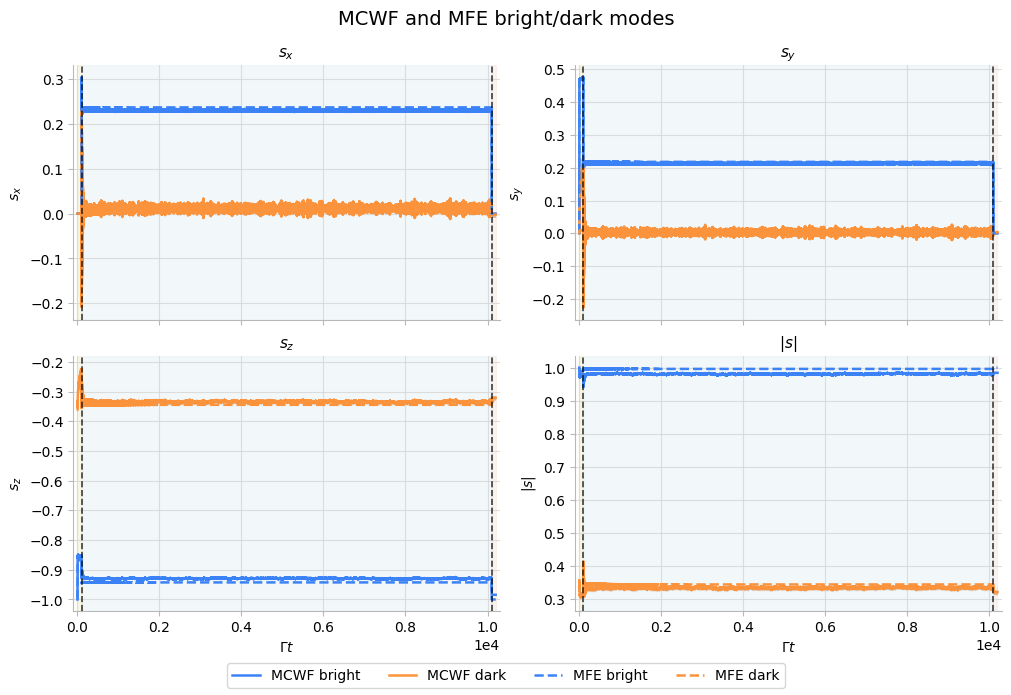

In [5]:
mcwf_bright = mcwf_moments.J_modes.bright
mcwf_dark = mcwf_moments.J_modes.dark
mode_fig, mode_axes = plot_spin_components(
    mcwf_moments.J_modes.t,
    (mcwf_bright.x, mcwf_dark.x),
    (mcwf_bright.y, mcwf_dark.y),
    (mcwf_bright.z, mcwf_dark.z),
    (mcwf_bright.length, mcwf_dark.length),
    x_sem=(mcwf_bright.x_sem, mcwf_dark.x_sem),
    y_sem=(mcwf_bright.y_sem, mcwf_dark.y_sem),
    z_sem=(mcwf_bright.z_sem, mcwf_dark.z_sem),
    length_sem=(mcwf_bright.length_sem, mcwf_dark.length_sem),
    labels=("MCWF bright", "MCWF dark"),
    phase_protocol=mcwf_moments.metadata.phase_protocol,
    shade_index=2,
    linestyle="-",
    spin_symbol="s",
    title="MCWF and MFE bright/dark modes",
)

mfe_bright = mfe_moments.J_modes.bright
mfe_dark = mfe_moments.J_modes.dark
mode_fig, mode_axes = plot_spin_components(
    mfe_moments.J_modes.t,
    (mfe_bright.x, mfe_dark.x),
    (mfe_bright.y, mfe_dark.y),
    (mfe_bright.z, mfe_dark.z),
    (mfe_bright.length, mfe_dark.length),
    labels=("MFE bright", "MFE dark"),
    phase_protocol=mfe_moments.metadata.phase_protocol,
    shade_index=2,
    linestyle="--",
    axes=mode_axes,
    spin_symbol="s",
    title="MCWF and MFE bright/dark modes",
)

# Per-panel time labels leave the shared figure legend unobstructed.
mode_fig.supxlabel("")
plt.setp(mode_axes[2:], xlabel=r"$\Gamma t$")

save_figure(mode_fig, output_dir / "collective_modes.png" if save_plots else None)


## Phase-2 dark-mode traces


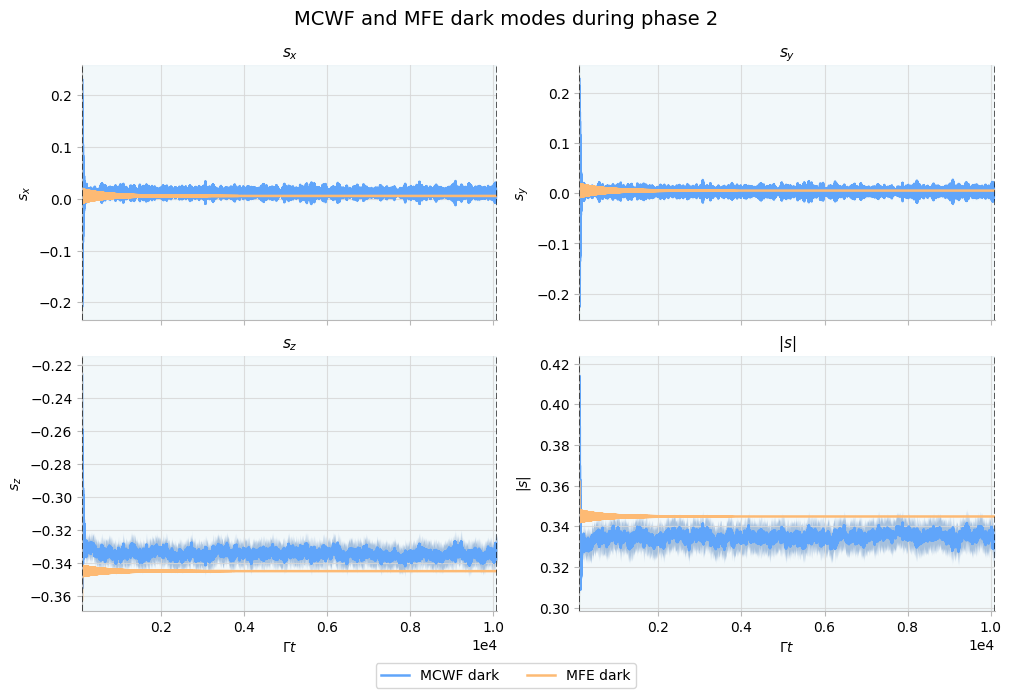

In [16]:
mcwf_dark = mcwf_moments.J_modes.dark
phase_2_t, phase_2_series = extract_family_phase_series(
    mcwf_moments.J_modes.t,
    (mcwf_dark.x, mcwf_dark.y, mcwf_dark.z, mcwf_dark.length),
    mcwf_moments.metadata.phase_protocol,
    family_phase_index=1,
)
phase_2_dark_components = phase_2_series[:3]
phase_2_sems = (None, None, None, None)
if mcwf_dark.x_sem is not None:
    _, phase_2_sems = extract_family_phase_series(
        mcwf_moments.J_modes.t,
        (mcwf_dark.x_sem, mcwf_dark.y_sem, mcwf_dark.z_sem, mcwf_dark.length_sem),
        mcwf_moments.metadata.phase_protocol,
        family_phase_index=1,
    )
dark_fig, dark_axes = plot_spin_components(
    phase_2_t,
    *phase_2_series,
    x_sem=phase_2_sems[0],
    y_sem=phase_2_sems[1],
    z_sem=phase_2_sems[2],
    length_sem=phase_2_sems[3],
    labels=("MCWF dark",),
    phase_protocol=mcwf_moments.metadata.phase_protocol,
    colour_family_index=0,
    shade_index=1,
    spin_symbol="s",
    title="MCWF and MFE dark modes during phase 2",
)

mfe_dark = mfe_moments.J_modes.dark
mfe_phase_2_t, mfe_phase_2_series = extract_family_phase_series(
    mfe_moments.J_modes.t,
    (mfe_dark.x, mfe_dark.y, mfe_dark.z, mfe_dark.length),
    mfe_moments.metadata.phase_protocol,
    family_phase_index=1,
)
mfe_phase_2_dark_components = mfe_phase_2_series[:3]
dark_fig, dark_axes = plot_spin_components(
    mfe_phase_2_t,
    *mfe_phase_2_series,
    labels=("MFE dark",),
    phase_protocol=mfe_moments.metadata.phase_protocol,
    colour_family_index=1,
    shade_index=1,
    axes=dark_axes,
    spin_symbol="s",
    title="MCWF and MFE dark modes during phase 2",
)
plt.setp(dark_axes, xlim=(phase_2_t[0], phase_2_t[-1]))
dark_fig.supxlabel("")
plt.setp(dark_axes[2:], xlabel=r"$\Gamma t$")
save_figure(dark_fig, output_dir / "phase_2_dark_mode.png" if save_plots else None)


## Windowed dark-mode harmonic analysis


In [7]:
window_duration = 200.0 / Gamma
step_duration = window_duration / 4
min_fit_r_squared = 0.9
minimum_cycles = 3.0
minimum_samples_per_period = 8.0

if np.max(np.diff(phase_2_t)) > saved_time_step * (1.0 + 1e-7):
    raise ValueError("The cached saved-time grid is too coarse for this analysis.")

dark_harmonic_analysis = compute_windowed_harmonic_analysis(
    phase_2_t,
    phase_2_dark_components,
    window_duration=window_duration,
    step_duration=step_duration,
    min_fit_r_squared=0.0,
)
harmonic_quality = compute_harmonic_quality(
    dark_harmonic_analysis,
    sample_spacing=phase_2_t[1] - phase_2_t[0],
    window_duration=window_duration,
    labels=("MCWF dark x", "MCWF dark y", "MCWF dark z"),
    min_fit_r_squared=min_fit_r_squared,
    minimum_cycles=minimum_cycles,
    minimum_samples_per_period=minimum_samples_per_period,
    verbose=True,
)

mfe_dark_harmonic_analysis = compute_windowed_harmonic_analysis(
    mfe_phase_2_t,
    mfe_phase_2_dark_components,
    window_duration=window_duration,
    step_duration=step_duration,
    min_fit_r_squared=0.0,
)
mfe_harmonic_quality = compute_harmonic_quality(
    mfe_dark_harmonic_analysis,
    sample_spacing=mfe_phase_2_t[1] - mfe_phase_2_t[0],
    window_duration=window_duration,
    labels=("MFE dark x", "MFE dark y", "MFE dark z"),
    min_fit_r_squared=min_fit_r_squared,
    minimum_cycles=minimum_cycles,
    minimum_samples_per_period=minimum_samples_per_period,
    verbose=True,
)


Failure counts can overlap. A flagged fit is not a detection or a non-detection.
Curve              Candidate   No fit   Low R²  Few cycles  Too coarse  Accepted
MCWF dark x              197        0      197           0           0         0
  R² min/median/max: 0.166, 0.421, 0.751
MCWF dark y              197        0      197           0           0         0
  R² min/median/max: 0.169, 0.420, 0.756
MCWF dark z              131       66      131          23           0         0
  R² min/median/max: 0.143, 0.353, 0.665
MFE dark x               197        0        0           0           0       197
  R² min/median/max: 0.990, 0.992, 0.992
MFE dark y               197        0        0           0           0       197
  R² min/median/max: 0.990, 0.992, 0.992
MFE dark z               197        0        1           0           0       196
  R² min/median/max: 0.875, 0.992, 0.992


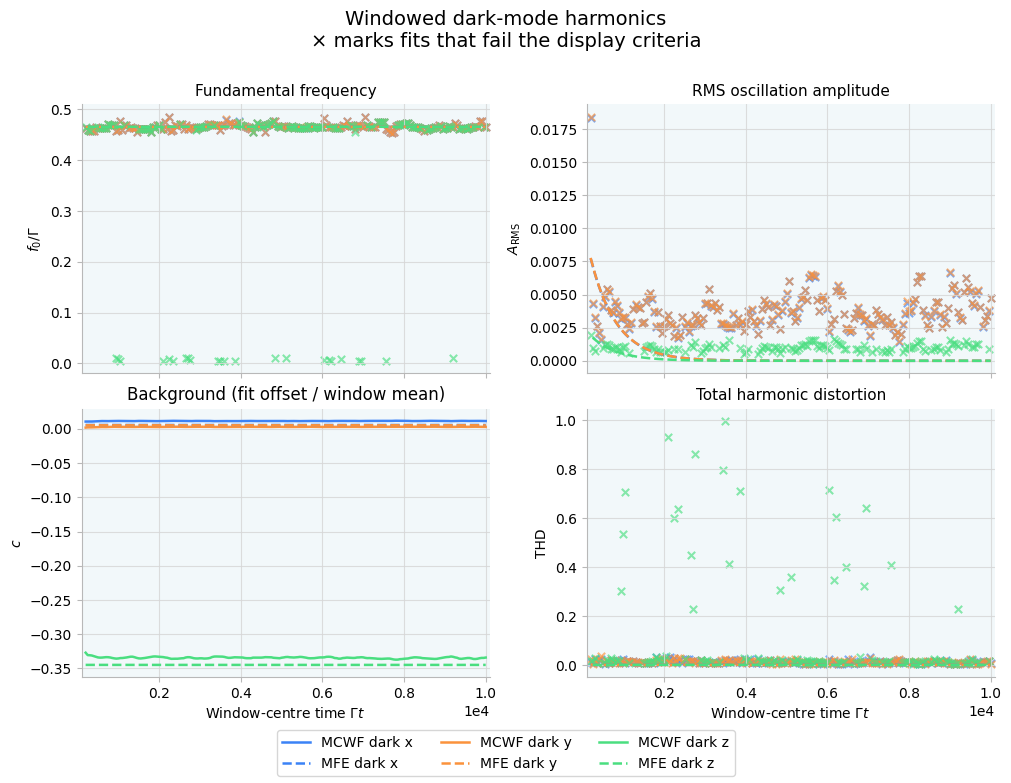

In [8]:
harmonic_fig, harmonic_axes = plot_harmonic_sweep(
    Gamma * dark_harmonic_analysis.window_centers,
    dark_harmonic_analysis.fundamental_frequencies.T / Gamma,
    dark_harmonic_analysis.total_harmonic_distortions.T,
    dark_harmonic_analysis.rms_amplitudes.T,
    dark_harmonic_analysis.offsets.T,
    quality_masks=harmonic_quality.T,
    labels=("MCWF dark x", "MCWF dark y", "MCWF dark z"),
    parameter_label=r"Window-centre time $\Gamma t$",
    family_phase_index=1,
    shade_index=2,
    title="Windowed dark-mode harmonics",
)
harmonic_fig, harmonic_axes = plot_harmonic_sweep(
    Gamma * mfe_dark_harmonic_analysis.window_centers,
    mfe_dark_harmonic_analysis.fundamental_frequencies.T / Gamma,
    mfe_dark_harmonic_analysis.total_harmonic_distortions.T,
    mfe_dark_harmonic_analysis.rms_amplitudes.T,
    mfe_dark_harmonic_analysis.offsets.T,
    quality_masks=mfe_harmonic_quality.T,
    labels=("MFE dark x", "MFE dark y", "MFE dark z"),
    parameter_label=r"Window-centre time $\Gamma t$",
    family_phase_index=1,
    shade_index=2,
    linestyle="--",
    axes=harmonic_axes,
)
harmonic_axes[0].set_ylabel(r"$f_0/\Gamma$")
harmonic_axes[2].set_title("Background (fit offset / window mean)")
harmonic_fig.suptitle("Windowed dark-mode harmonics\n× marks fits that fail the display criteria", y=1.10, fontsize=14)
save_figure(harmonic_fig, output_dir / "dark_mode_harmonics.png" if save_plots else None)


## Early-time damped-oscillation fit


In [9]:
from post_analysis.short_time_oscillations import compute_short_time_dark_mode_analysis

dark_decay_analysis = compute_short_time_dark_mode_analysis(
    mcwf_moments,
    duration=200.0 / Gamma,
    reference_frequencies=mfe_dark_harmonic_analysis.fundamental_frequencies,
    num_resamples=200,
    confidence_level=0.95,
    seed=1234,
    verbose=True,
)


Fitting a single exponentially damped sinusoid with a linear background.
Frequency band: (0.2328308786050463, 0.6984926358151389) ; intervals are conditional on this model.
Bootstrap: 25/200
Bootstrap: 50/200
Bootstrap: 75/200
Bootstrap: 100/200
Bootstrap: 125/200
Bootstrap: 150/200
Bootstrap: 175/200
Bootstrap: 200/200
Dark x: gamma/Gamma=0.049765, f/Gamma=0.46735, R²=0.973
  95% bootstrap interval for gamma/Gamma: None; usable resamples: 125/200; parameter bound: False
  The fit is not stable enough to report an interval.
Dark y: gamma/Gamma=0.05, f/Gamma=0.46736, R²=0.973
  95% bootstrap interval for gamma/Gamma: None; usable resamples: 118/200; parameter bound: True
  The fit is not stable enough to report an interval.
Dark z: gamma/Gamma=0.05, f/Gamma=0.46805, R²=0.830
  95% bootstrap interval for gamma/Gamma: None; usable resamples: 41/200; parameter bound: True
  The fit is not stable enough to report an interval.


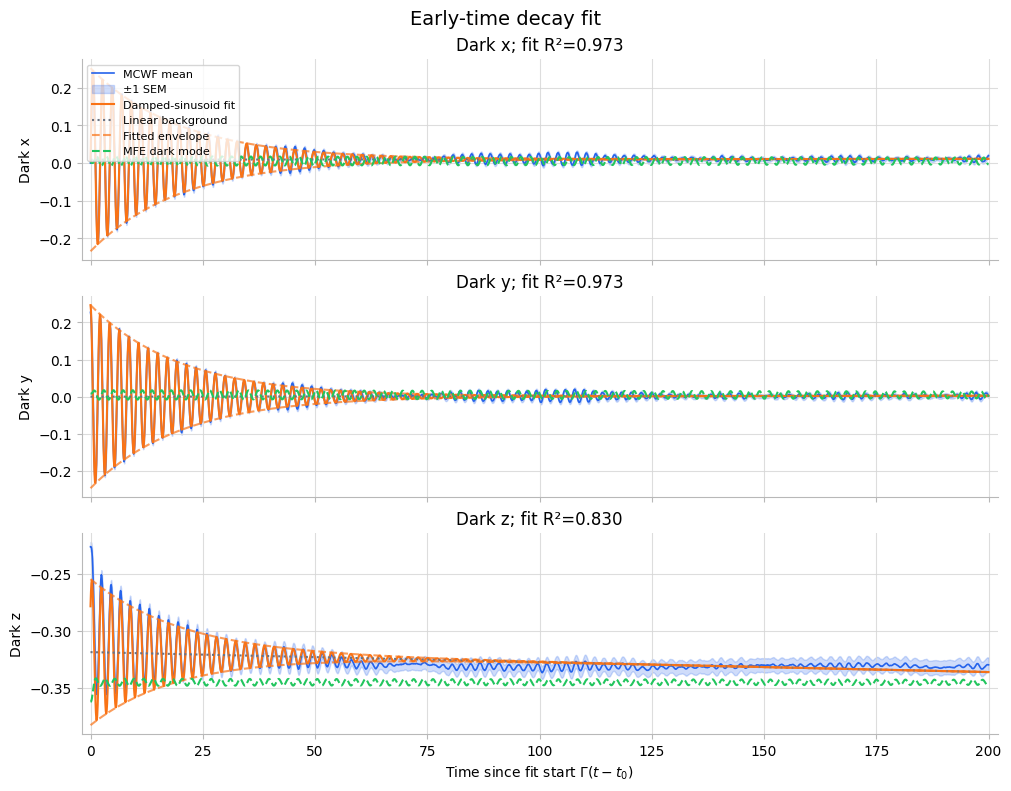

In [10]:
from common.plotting.harmonic_analysis import plot_damped_oscillations

mfe_dark = mfe_moments.J_modes.dark
decay_fig, decay_axes = plot_damped_oscillations(
    dark_decay_analysis.t,
    dark_decay_analysis.components,
    dark_decay_analysis.fits,
    labels=("Dark x", "Dark y", "Dark z"),
    sem=dark_decay_analysis.sem,
    reference_t=mfe_moments.t,
    reference_series=(mfe_dark.x, mfe_dark.y, mfe_dark.z),
    reference_label="MFE dark mode",
    time_scale=Gamma,
    time_label=r"Time since fit start $\Gamma(t-t_0)$",
)
save_figure(decay_fig, output_dir / "early_dark_mode_decay.png" if save_plots else None)


## Stored outputs


In [11]:
{
    "delta/(N*Gamma)": delta_factor,
    "first moments (R, T, G, 8)": mcwf_moments.generator_moments.first_moments.shape,
    "packed second moments (R, T, K)": mcwf_moments.generator_moments.second_moments.shape,
    "mean first moments": mcwf_moments.mean_generator_moments.first_moments.shape,
    "group couplings": mcwf_moments.metadata.omega_groups,
    "MFE solve succeeded": mfe_result.success,
    "MCWF/MFE saved grids match": np.array_equal(mcwf_moments.t, mfe_moments.t),
    "phase-2 samples": phase_2_t.size,
    "harmonic window duration": window_duration,
    "harmonic step duration": step_duration,
    "minimum fit R-squared": min_fit_r_squared,
    "accepted harmonic windows": {
        "MCWF": harmonic_quality.sum(axis=0),
        "MFE": mfe_harmonic_quality.sum(axis=0),
    },
}


{'delta/(N*Gamma)': 0.283,
 'first moments (R, T, G, 8)': (500, 102001, 2, 8),
 'packed second moments (R, T, K)': (500, 102001, 136),
 'mean first moments': (1, 102001, 2, 8),
 'group couplings': (0.6666666666666666, 1.3333333333333335),
 'MFE solve succeeded': True,
 'MCWF/MFE saved grids match': True,
 'phase-2 samples': 100001,
 'harmonic window duration': 200.0,
 'harmonic step duration': 50.0,
 'minimum fit R-squared': 0.9,
 'window diagnostics': {'MCWF': {'x': {'candidate': 197,
    'no fit': 0,
    'low R-squared': 197,
    'too few cycles': 0,
    'insufficient saved resolution': 0,
    'accepted': 0,
    'R-squared min/median/max': (np.float64(0.16592003681280187),
     np.float64(0.42097569597158135),
     np.float64(0.7507269749280918))},
   'y': {'candidate': 197,
    'no fit': 0,
    'low R-squared': 197,
    'too few cycles': 0,
    'insufficient saved resolution': 0,
    'accepted': 0,
    'R-squared min/median/max': (np.float64(0.1692158130844973),
     np.float64(0.42